# Eye Model — Serena Raju + MRL
Gozluk ve farkli kosullara dayanikli model egitimi

In [ ]:
# BLOK 1 — Kaggle Kurulum
!pip install -q kaggle
from google.colab import files
files.upload()  # kaggle.json yukleyin
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json
print('Kaggle hazir!')

Saving kaggle.json to kaggle (1).json
Kaggle hazir!


In [ ]:
# BLOK 2 — Serena Raju Indir
import os
!kaggle datasets download -d serenaraju/yawn-eye-dataset-new
!mkdir -p /content/datasets/original
!unzip -q yawn-eye-dataset-new.zip -d /content/datasets/original
for cls in ['Closed', 'Open']:
    p = f'/content/datasets/original/dataset_new/train/{cls}'
    if os.path.exists(p):
        print(f'train/{cls}: {len(os.listdir(p))} dosya')
print('Serena Raju indirildi.')

Dataset URL: https://www.kaggle.com/datasets/serenaraju/yawn-eye-dataset-new
License(s): unknown
100% 161M/161M [00:01<00:00, 155MB/s]

train/Closed: 617 dosya
train/Open: 617 dosya
Serena Raju indirildi.


In [ ]:
# BLOK 3 — MRL Indir
import os
!kaggle datasets download -d prasadvpatil/mrl-dataset
!unzip -q mrl-dataset.zip -d /content/datasets/mrl
mrl_path = '/content/datasets/mrl'
for root, dirs, files_list in os.walk(mrl_path):
    level = root.replace(mrl_path, '').count(os.sep)
    if level < 3:
        indent = ' ' * 2 * level
        n = len([f for f in files_list if f.lower().endswith(('.jpg','.png','.pgm'))])
        print(f'{indent}{os.path.basename(root)}/ ({n} img)')
print('MRL indirildi.')

Dataset URL: https://www.kaggle.com/datasets/prasadvpatil/mrl-dataset
License(s): CC0-1.0
100% 22.6M/22.6M [00:00<00:00, 110MB/s] 

mrl/ (0 img)
  train/ (0 img)
    Closed_Eyes/ (2000 img)
    Open_Eyes/ (2000 img)
MRL indirildi.


In [ ]:
# BLOK 4 — MRL
import os
!kaggle datasets download -d kutaykutlu/drowsiness-detection
!mkdir -p /content/datasets/cew
!unzip -q drowsiness-detection.zip -d /content/datasets/cew
cew_path = '/content/datasets/cew'
print('CEW klasor yapisi:')
for root, dirs, files_list in os.walk(cew_path):
    level = root.replace(cew_path, '').count(os.sep)
    if level < 4:
        indent = ' ' * 2 * level
        n = len([f for f in files_list if f.lower().endswith(('.jpg','.jpeg','.png','.pgm'))])
        print(f'{indent}{os.path.basename(root)}/ ({n} img)')
print('CEW indirildi.')

Dataset URL: https://www.kaggle.com/datasets/kutaykutlu/drowsiness-detection
License(s): unknown
100% 180M/180M [00:02<00:00, 84.0MB/s]

CEW klasor yapisi:
cew/ (0 img)
  open_eye/ (24000 img)
  closed_eye/ (24000 img)
CEW indirildi.


In [ ]:
# BLOK 5 — Hedef Klasorler Olustur
import shutil, random, cv2, os
random.seed(42)

hedef = {
    'train': {
        'Closed': '/content/datasets/eye_combined/train/Closed',
        'Open':   '/content/datasets/eye_combined/train/Open'
    },
    'test': {
        'Closed': '/content/datasets/eye_combined/test/Closed',
        'Open':   '/content/datasets/eye_combined/test/Open'
    }
}
for split in hedef.values():
    for path in split.values():
        os.makedirs(path, exist_ok=True)
print('Klasorler olusturuldu.')

Klasorler olusturuldu.


In [ ]:
# BLOK 6 — Serena Raju Kopyala
for split in ['train', 'test']:
    for cls in ['Closed', 'Open']:
        src = f'/content/datasets/original/dataset_new/{split}/{cls}'
        if not os.path.exists(src): continue
        for f in os.listdir(src):
            if f.lower().endswith(('.jpg','.jpeg','.png')):
                shutil.copy(os.path.join(src, f),
                            os.path.join(hedef[split][cls], f'orig_{f}'))
print('Serena Raju kopyalandi.')
for split in ['train','test']:
    for cls in ['Closed','Open']:
        print(f'  {split}/{cls}: {len(os.listdir(hedef[split][cls]))} goruntu')

Serena Raju kopyalandi.
  train/Closed: 617 goruntu
  train/Open: 617 goruntu
  test/Closed: 109 goruntu
  test/Open: 109 goruntu


In [ ]:
# BLOK 7 — MRL Kopyala
mrl_path = '/content/datasets/mrl'
mrl_counter = 0
for root, dirs, files_list in os.walk(mrl_path):
    folder = os.path.basename(root)
    if folder == 'Open_Eyes': label = 'Open'
    elif folder == 'Closed_Eyes': label = 'Closed'
    else: continue
    for f in [x for x in files_list if x.lower().endswith(('.jpg','.png','.pgm'))]:
        split = 'train' if random.random() < 0.8 else 'test'
        img = cv2.imread(os.path.join(root, f))
        if img is None: continue
        cv2.imwrite(os.path.join(hedef[split][label], f'mrl_{mrl_counter}.jpg'), img)
        mrl_counter += 1
print(f'MRL kopyalandi: {mrl_counter} goruntu')
for split in ['train','test']:
    for cls in ['Closed','Open']:
        print(f'  {split}/{cls}: {len(os.listdir(hedef[split][cls]))} goruntu')

MRL kopyalandi: 4000 goruntu
  train/Closed: 2218 goruntu
  train/Open: 2214 goruntu
  test/Closed: 508 goruntu
  test/Open: 512 goruntu


In [ ]:
# BLOK 8 — CEW Kopyala
cew_path = '/content/datasets/cew'
cew_counter = 0

closed_keywords = ['closed', 'closedlefteyes', 'closedrighteyes', 'drowsy', '0', 'close_eye', 'closed_eye']
open_keywords   = ['open', 'openlefteyes', 'openrighteyes', 'non_drowsy', 'alert', '1', 'open_eye']

for root, dirs, files_list in os.walk(cew_path):
    folder = os.path.basename(root).lower()
    if folder in closed_keywords: label = 'Closed'
    elif folder in open_keywords: label = 'Open'
    else: continue
    imgs = [x for x in files_list if x.lower().endswith(('.jpg','.jpeg','.png','.pgm'))]
    for f in imgs:
        split = 'train' if random.random() < 0.8 else 'test'
        img = cv2.imread(os.path.join(root, f))
        if img is None: continue
        cv2.imwrite(os.path.join(hedef[split][label], f'cew_{cew_counter}.jpg'), img)
        cew_counter += 1

print(f'CEW kopyalandi: {cew_counter} goruntu')
print('--- TOPLAM ---')
for split in ['train','test']:
    for cls in ['Closed','Open']:
        print(f'  {split}/{cls}: {len(os.listdir(hedef[split][cls]))} goruntu')

CEW kopyalandi: 48000 goruntu
--- TOPLAM ---
  train/Closed: 21467 goruntu
  train/Open: 21444 goruntu
  test/Closed: 5259 goruntu
  test/Open: 5282 goruntu


In [ ]:
# BLOK 9 — Generator
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator

IMG_SHAPE  = 128
BATCH_SIZE = 32
BASE_DIR   = '/content/datasets/eye_combined'

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    shear_range=0.1,
    zoom_range=0.15,
    horizontal_flip=True,
    brightness_range=[0.6, 1.4],
    fill_mode='nearest'
)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    BASE_DIR+'/train',
    target_size=(IMG_SHAPE, IMG_SHAPE),
    batch_size=BATCH_SIZE,
    classes=['Closed','Open'],
    class_mode='binary',
    shuffle=True
)
val_generator = val_datagen.flow_from_directory(
    BASE_DIR+'/test',
    target_size=(IMG_SHAPE, IMG_SHAPE),
    batch_size=BATCH_SIZE,
    classes=['Closed','Open'],
    class_mode='binary',
    shuffle=False
)
print('Siniflar:', train_generator.class_indices)
print('Train:', train_generator.n, '| Test:', val_generator.n)

Found 42911 images belonging to 2 classes.
Found 10541 images belonging to 2 classes.
Siniflar: {'Closed': 0, 'Open': 1}
Train: 42911 | Test: 10541


In [ ]:
# BLOK 10 — Model Tanimla
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from google.colab import drive

drive.mount('/content/drive')
SAVE_DIR = '/content/drive/MyDrive/drowsiness_models/'
os.makedirs(SAVE_DIR, exist_ok=True)

eye_model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(IMG_SHAPE, IMG_SHAPE, 3)),
    BatchNormalization(), MaxPooling2D(2,2),
    Conv2D(64, (3,3), activation='relu'),
    BatchNormalization(), MaxPooling2D(2,2),
    Conv2D(128, (3,3), activation='relu'),
    BatchNormalization(), MaxPooling2D(2,2),
    Flatten(),
    Dense(128, activation='relu'), Dropout(0.5),
    Dense(64,  activation='relu'), Dropout(0.3),
    Dense(1,   activation='sigmoid')
])
eye_model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
eye_model.summary()

Mounted at /content/drive


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 126, 126, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 61, 61, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 28, 28, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,313,857 (12.64 MB)

 Trainable params: 3,313,409 (12.64 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
# BLOK 11 — Egitim
callbacks = [
    EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True, verbose=1),
    ReduceLROnPlateau(monitor='val_loss', factor=0.3, patience=4, min_lr=1e-6, verbose=1),
    ModelCheckpoint(SAVE_DIR+'eye_model_cew_mrl_best.h5',
                    monitor='val_accuracy', save_best_only=True, verbose=1)
]
history = eye_model.fit(
    train_generator,
    epochs=30,
    validation_data=val_generator,
    callbacks=callbacks
)

Epoch 1/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.7422 - loss: 1.3379
Epoch 1: val_accuracy improved from None to 0.65127, saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5



Epoch 1: finished saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 263s 190ms/step - accuracy: 0.8020 - loss: 0.7288 - val_accuracy: 0.6513 - val_loss: 0.5577 - learning_rate: 0.0010
Epoch 2/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.8954 - loss: 0.2691
Epoch 2: val_accuracy improved from 0.65127 to 0.92837, saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5



Epoch 2: finished saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 244s 182ms/step - accuracy: 0.9105 - loss: 0.2315 - val_accuracy: 0.9284 - val_loss: 0.2782 - learning_rate: 0.0010
Epoch 3/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 176ms/step - accuracy: 0.9440 - loss: 0.1538
Epoch 3: val_accuracy did not improve from 0.92837
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 243s 181ms/step - accuracy: 0.9520 - loss: 0.1349 - val_accuracy: 0.8799 - val_loss: 0.3863 - learning_rate: 0.0010
Epoch 4/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.9651 - loss: 0.1019
Epoch 4: val_accuracy did not improve from 0.92837
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 239s 178ms/step - accuracy: 0.9677 - loss: 0.0965 - val_accuracy: 0.6143 - val_loss: 0.6504 - learning_rate: 0.0010
Epoch 5/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.9715 - loss: 0.0832
Epoch 5: val_accuracy did not improve from 0.92837
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 238


Epoch 6: finished saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 239s 178ms/step - accuracy: 0.9767 - loss: 0.0696 - val_accuracy: 0.9839 - val_loss: 0.0673 - learning_rate: 0.0010
Epoch 7/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9804 - loss: 0.0657
Epoch 7: val_accuracy improved from 0.98387 to 0.99137, saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5



Epoch 7: finished saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 237s 177ms/step - accuracy: 0.9807 - loss: 0.0624 - val_accuracy: 0.9914 - val_loss: 0.0262 - learning_rate: 0.0010
Epoch 8/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9829 - loss: 0.0567
Epoch 8: val_accuracy improved from 0.99137 to 0.99175, saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5


...


Epoch 16: finished saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 244s 182ms/step - accuracy: 0.9913 - loss: 0.0269 - val_accuracy: 0.9946 - val_loss: 0.0159 - learning_rate: 3.0000e-04
Epoch 17/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.9924 - loss: 0.0267
Epoch 17: val_accuracy did not improve from 0.99459
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 244s 182ms/step - accuracy: 0.9921 - loss: 0.0270 - val_accuracy: 0.9934 - val_loss: 0.0173 - learning_rate: 3.0000e-04
Epoch 18/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.9916 - loss: 0.0268
Epoch 18: val_accuracy did not improve from 0.99459
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 241s 180ms/step - accuracy: 0.9919 - loss: 0.0268 - val_accuracy: 0.9935 - val_loss: 0.0214 - learning_rate: 3.0000e-04
Epoch 19/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 174ms/step - accuracy: 0.9919 - loss: 0.0231
Epoch 19: val_accuracy did not improve from 0.99459
1341/1341 ━━━━━


Epoch 21: finished saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 242s 180ms/step - accuracy: 0.9935 - loss: 0.0213 - val_accuracy: 0.9948 - val_loss: 0.0152 - learning_rate: 9.0000e-05
Epoch 22/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 172ms/step - accuracy: 0.9930 - loss: 0.0225
Epoch 22: val_accuracy improved from 0.99478 to 0.99497, saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5



Epoch 22: finished saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 238s 178ms/step - accuracy: 0.9930 - loss: 0.0223 - val_accuracy: 0.9950 - val_loss: 0.0144 - learning_rate: 9.0000e-05
Epoch 23/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9928 - loss: 0.0204
Epoch 23: val_accuracy did not improve from 0.99497
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 237s 177ms/step - accuracy: 0.9931 - loss: 0.0206 - val_accuracy: 0.9948 - val_loss: 0.0149 - learning_rate: 9.0000e-05
Epoch 24/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9935 - loss: 0.0215
Epoch 24: val_accuracy did not improve from 0.99497
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 236s 176ms/step - accuracy: 0.9937 - loss: 0.0205 - val_accuracy: 0.9942 - val_loss: 0.0150 - learning_rate: 9.0000e-05
Epoch 25/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.9937 - loss: 0.0192
Epoch 25: val_accuracy did not improve from 0.99497
1341/1341 ━━━━━


Epoch 27: finished saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 243s 181ms/step - accuracy: 0.9936 - loss: 0.0202 - val_accuracy: 0.9951 - val_loss: 0.0132 - learning_rate: 9.0000e-05
Epoch 28/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.9942 - loss: 0.0183
Epoch 28: val_accuracy improved from 0.99507 to 0.99526, saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5



Epoch 28: finished saving model to /content/drive/MyDrive/drowsiness_models/eye_model_cew_mrl_best.h5
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 244s 182ms/step - accuracy: 0.9937 - loss: 0.0196 - val_accuracy: 0.9953 - val_loss: 0.0147 - learning_rate: 9.0000e-05
Epoch 29/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 173ms/step - accuracy: 0.9937 - loss: 0.0194
Epoch 29: val_accuracy did not improve from 0.99526
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 242s 181ms/step - accuracy: 0.9937 - loss: 0.0199 - val_accuracy: 0.9951 - val_loss: 0.0141 - learning_rate: 9.0000e-05
Epoch 30/30
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 0s 171ms/step - accuracy: 0.9945 - loss: 0.0166
Epoch 30: val_accuracy did not improve from 0.99526
1341/1341 ━━━━━━━━━━━━━━━━━━━━ 236s 176ms/step - accuracy: 0.9945 - loss: 0.0176 - val_accuracy: 0.9951 - val_loss: 0.0135 - learning_rate: 9.0000e-05
Restoring model weights from the end of the best epoch: 27.


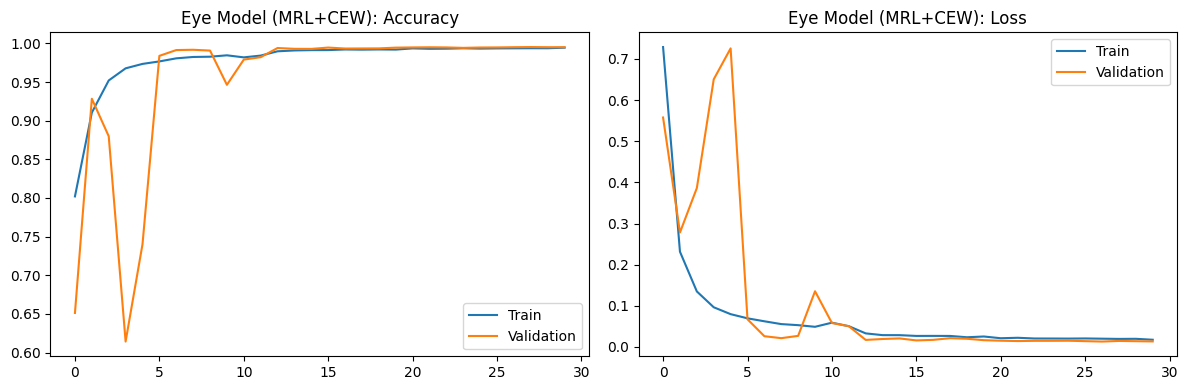

330/330 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step


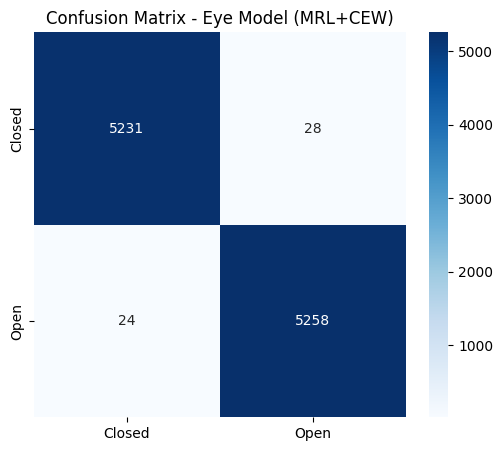

              precision    recall  f1-score   support

      Closed       1.00      0.99      1.00      5259
        Open       0.99      1.00      1.00      5282

    accuracy                           1.00     10541
   macro avg       1.00      1.00      1.00     10541
weighted avg       1.00      1.00      1.00     10541



In [ ]:
# BLOK 12 — Grafik ve Confusion Matrix
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import numpy as np

plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Eye Model (MRL+CEW): Accuracy'); plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Eye Model (MRL+CEW): Loss'); plt.legend()
plt.tight_layout(); plt.show()

val_generator.reset()
Y_pred = eye_model.predict(val_generator)
y_pred = (Y_pred > 0.5).astype(int).flatten()
y_true = val_generator.classes

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Closed','Open'], yticklabels=['Closed','Open'])
plt.title('Confusion Matrix - Eye Model (MRL+CEW)'); plt.show()
print(classification_report(y_true, y_pred, target_names=['Closed','Open']))

In [ ]:
# BLOK 13 — Kaydet ve Indir
from google.colab import files
eye_model.save('eye_model_final.h5')
files.download('eye_model_final.h5')
print('Bitti!')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Bitti!
